In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

# Jupyter may start the kernel in the repository root or in notebooks/.
PROJECT_ROOT = Path.cwd() if Path("data").is_dir() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


In [ ]:
import matplotlib.pyplot as plt
import random
import math
import seaborn as sns

In [ ]:
data=pd.read_csv(DATA_DIR / "train.csv",index_col="Id")
prev_data=pd.read_csv(DATA_DIR / "prev.csv",index_col="Id")


In [ ]:
data.head()

In [ ]:
prev_data.head()

# L’apprentissage par arbre de décision
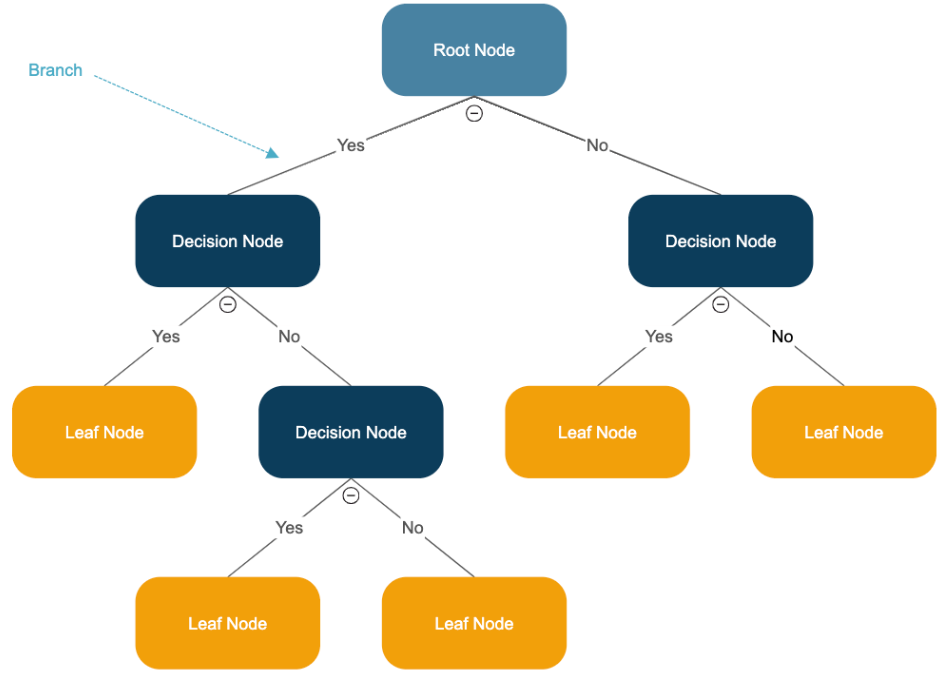

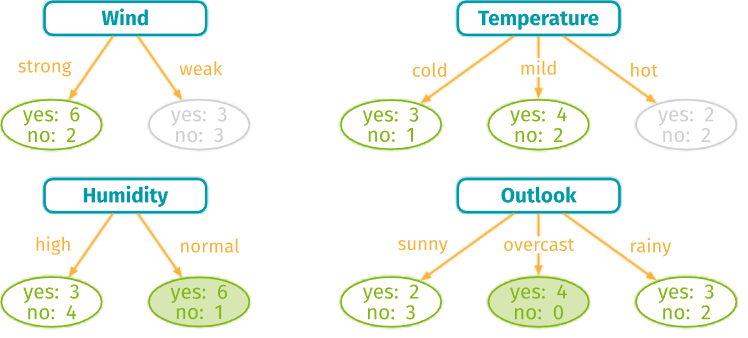

In [ ]:
#on garde les colonnes numériques dans le train et le prev

data_num=data.drop(columns=['espece', 'ile_origine', 'sexe'])
prev_data_num=prev_data[data_num.columns]

# on crée les tableaux numpy

X=data_num.to_numpy()

Xprev=prev_data_num.to_numpy()

# la colonne de classification numpy

Y=data['espece'].to_numpy()

In [ ]:
# on va avoir besoin de bien coder le nom des colonnes

# petit test pour voir l'ordre dans data
data_num.head(), prev_data_num.head()

In [ ]:
nom_col=list(data_num.columns)

# on vérifie que l'ordre est le même
nom_col

In [ ]:
# on fait quand même un petit test pour se rassurer
data_num[nom_col[2]][0], X[0,2]

**Les étapes du code**
* On définit la fonction entropie (qui sera notre critère de coupure)
* On définit la fonction meilleure_coupure (teste toutes les colonnes disonibles et les coupures optimales pour chaque colonne)
* On définit la fonction récursive construire_arbre.
* On définit la fonction de classification d'un nouvel individu à partir d'un arbre. On donne à la suite une variante plus compliquée qui permet de visualiser le chemin parcouru dans l'arbre (optionnel).
* On étend la fonction précédente à un tableau de nouveaux individus.
* On présente une fonction de visualisation (affichage) de l'arbre (optionnel). 

# C'est quoi l'entropie ?


***C’est une mesure du désordre ou de l’incertitude.***

👉 Entropie = niveau de confusion dans les données


1. **Entropie** = 0 → tout est identique (parfaitement ordonné)

2. **Entropie élevée** → tout est mélangé (incertain)


-> ça sert à mesurer à quel point les données sont "pures" ou "mélangées"

🎯 Pourquoi c’est important ?

Il sert principalement à calculer **le gain d'information**, ce qui aide à déterminer la meilleure coupure. 

# Fonction entropie(y)

In [ ]:
def entropie(y):
    """
    H(y) = -Σ p_k * log2(p_k)
    y : array 1D
    """
    n = len(y) #On calcule le nombre total d’éléments dans y, nombre d'individus
    
    if n == 0: #Cas particulier : Si y est vide → entropie = 0
        return 0.0
        
    _, comptes = np.unique(y, return_counts=True)
    
    print(comptes)
    
    # np.unique(y) trouve les valeurs uniques et
    # return_counts=True donne combien de fois chaque valeur apparaît
    
    p = comptes / n # on transforme les comptes en probabilités :
    
    # log2(0) indéfini → on filtre les p nuls (ne peuvent pas arriver avec unique)

    return float(-np.sum(p * np.log2(p)))

entropie(data['espece']), entropie(Y)

# C'est quoi le gain d'information ? 

**Le gain d'information indique à quel point une coupure est utile en mesurant combien elle réduit l'entropie.**

✅ « Gain d'information = dans quelle mesure les données gagnent en pureté après la coupure »

C'est-à-dire, l’entropie diminue et le gain d’information augmente.

En pratique, on choisit la division produisant le plus grand gain d’information à chaque nœud de l’arbre.

# Fonction meilleure_coupure(X, y, noms)

Fonction qui cherche **la meilleure coupure (split)** pour un arbre de décision.

👉 « Où dois-je diviser mes données pour qu'elles soient aussi « pures » que possible ? »

Pour ce faire, elle procède comme suit :


* Calculer l'entropie avant la division
* Tester toutes les divisions possibles
* Calculer l'entropie après chaque division
* Choisir la division qui maximise le gain d'information


*On va tester :*


* toutes les variables
* tous les seuils possibles


*La sortie :*


* nom de la variable
* index de la colonne
* seuil choisi
* gain d’information


***Types :***

X = données (features)

y = labels

noms = nom des colonnes

In [ ]:
def meilleure_coupure(X, y, noms):
    """
    Parcourt toutes les colonnes et tous les seuils candidats.
    Renvoie (nom_variable, index_colonne, seuil, gain).
    Renvoie (None, None, None, 0) si aucune coupure utile.

    X : 2D ndarray
    y : 1D ndarray

    la varible 'noms' fait référence au nom des colonnes. 
   
    """
    n_total       = len(y) #Nombre total d’exemples
    
    h_parent      = entropie(y) #Entropie AVANT séparation
    
    meilleur_gain = 0.0  #On initialise le meilleur gain à 0

    #Variables pour stocker le meilleur split
    
    meilleure_var = None
    meilleur_idx  = None
    meilleur_seuil = None

    #Boucle sur chaque variable
    
    #Pour chaque colonne :
        #j = index
        #nom = nom de la variable

    for j, nom in enumerate(noms):
        # on commence par trier les valeurs et réindexer la colonne j
        
        valeurs = X[:, j] #On prend la colonne j
        ordre   = np.argsort(valeurs) #On trie les indices selon les valeurs

        #On réordonne : 
        
        #1. les valeurs
        val_tri = valeurs[ordre] 
        #2. les labels
        y_tri   = y[ordre]

        # Balayage des points de coupure entre deux valeurs distinctes

        #Boucle sur les seuils
        
        #On teste toutes les positions possibles de coupure
        
        for i in range(1, n_total):
            if val_tri[i] == val_tri[i - 1]:
                continue

            seuil    = (val_tri[i - 1] + val_tri[i]) / 2
            y_gauche = y_tri[:i]
            y_droit  = y_tri[i:]

            #Calculer l'entropie après chaque division
            
            h_apres = (
                (i / n_total)            * entropie(y_gauche)
                + ((n_total - i) / n_total) * entropie(y_droit)
            )
            gain = h_parent - h_apres #indique à quel point une coupure est utile en mesurant combien elle réduit l'entropie

            #on met à jour si jamais on a un meilleur gain
            if gain > meilleur_gain:
                meilleur_gain  = gain
                meilleure_var  = nom
                meilleur_idx   = j
                meilleur_seuil = seuil

    return meilleure_var, meilleur_idx, meilleur_seuil, meilleur_gain

# petit test sur le tableau de départ
#meilleure_coupure(X, Y, nom_col)

# Fonction constuire_arbre(X, y, noms, profondeur_max, n_min)

Il y a trois **critères d'arret** classiques:

1. le nombre de questions
2. accuracy
3. le nombre d'individus


In [ ]:
"""
Arbre de classification — implémentation Python sans classes
Critère : entropie (gain d'information)

Un arbre est simplement un dictionnaire :
  - nœud feuille  : {"feuille": True,  "classe": "Gentoo", "n": 351}
  - nœud interne  : {"feuille": False, "variable": "epaisseur_bec_mm",
                      "seuil": 14.4,
                      "gauche": <sous-arbre>,   # condition VRAIE  (valeur <= seuil)
                      "droit":  <sous-arbre>}   # condition FAUSSE (valeur >  seuil)
"""



# ─────────────────────────────────────────────
#  Construction récursive
# ─────────────────────────────────────────────


def construire_arbre(X, y, noms, profondeur_max, n_min):
    """
    Construit l'arbre récursivement.

    Paramètres
    ----------
    X             : ndarray numpy 2D
    y             : ndarray numpy 1D
    noms          : nom des colonnes sous forme de liste 
    profondeur_max: profondeur maximale autorisée
    n_min         : nombre minimal d'exemples pour diviser un nœud

    Retourne un dictionnaire imbriqué représentant l'arbre.
    """
    
    # ── Critères d'arrêt ────────────────────
    if len(y) < n_min or profondeur_max == 0 or entropie(y) == 0.0:
        return _feuille(y)

    var, idx, seuil, gain = meilleure_coupure(X, y, noms)
    # rappel, meilleure_coupure renvoie (nom_variable, index_colonne, seuil, gain)

    if var is None:
        return _feuille(y)

    # ── Diviser ─────────────────────────────
    # on va regarder chaque ligne, pour la colonne idx, si elle est en dessous=TRUE ou au-dessus = FALSE
    masque   = X[:, idx] <= seuil
    # on récupére une suite booléenne
       
    X_g, y_g = X[masque],  y[masque]
    X_d, y_d = X[~masque], y[~masque]
    # on rappelle que qu'en numpy, un masque booléen appliqué à un tableau 2D sélectionne toujours des lignes 

    return {
        "feuille":  False,
        "variable": var,
        "index":    idx,
        "seuil":    seuil,
        "gain":     round(gain, 4),
        "n":        len(y),
        "gauche":   construire_arbre(X_g, y_g, noms, profondeur_max - 1, n_min),
        "droit":    construire_arbre(X_d, y_d, noms, profondeur_max - 1, n_min),
    }


def _feuille(y):
    """Crée un nœud feuille à partir d'un tableau d'étiquettes."""
    classes, comptes = np.unique(y, return_counts=True)
    classe_maj = classes[np.argmax(comptes)]
    return {
        "feuille": True,
        "classe":  str(classe_maj),
        "n":       len(y),
        "distrib": dict(zip(classes.tolist(), comptes.tolist())),
    }


In [ ]:
arbre = construire_arbre(X, Y, nom_col, 3, 5)
arbre

# Fonction _predire_un(arbre, ligne)

On définit une fonction qui :


1. prend un arbre de décision (arbre) et
2. une ligne de données (ligne)

**But :** prédire la classe d’un seul individu

La fonction s’appelle elle-même : ***elle est récursive**:* 


* descend dans l’arbre
* encore et encore
* jusqu’à trouver une feuille


*Cette fonction suit les règles de l’arbre pour classer un individu.*


In [ ]:
# parcourir l'arbre pour un nouvel individu

def _predire_un(arbre, ligne):
    """Descend l'arbre pour une seule ligne (numpy array 1D)."""
    
    #On vérifie : est-ce qu’on est arrivé à une feuille ? Une feuille = fin de l’arbre
    if arbre["feuille"]: 
        return arbre["classe"] #Si oui : on retourne la classe prédite

    #Sinon (pas une feuille), on teste une condition :

        #arbre["index"] → quelle variable regarder
        #arbre["seuil"] → valeur de coupure

    
    #est-ce que la valeur de la ligne ≤ seuil ?

    #Si OUI :

        #on va dans la branche gauche
        #et on recommence (récursion)
    
    if ligne[arbre["index"]] <= arbre["seuil"]: 
        return _predire_un(arbre["gauche"], ligne)

    #Si NON : 
        #On va dans la branche droite
        #et on continue jusqu’à une feuille
    else:
        return _predire_un(arbre["droit"],  ligne)


_predire_un(arbre, X[68,:]), Y[68]

In [ ]:
# OPTIONNEL 
# on peut faire une variante plus explicative de l'algorithme de prédiction précédent

def predire_et_expliquer(arbre, x):
    """
    x : une ligne — numpy array 1D, ou pandas Series (= nouvel individu).
    Affiche le chemin parcouru dans l'arbre et retourne la classe prédite.
    """
    # on transforme en ndarray si nécessaire
    if isinstance(x, pd.Series):
        x = x.to_numpy(dtype=float)

    noeud  = arbre
    niveau = 0

    while not noeud["feuille"]:
        var    = noeud["variable"]
        idx    = noeud["index"]
        seuil  = noeud["seuil"]
        valeur = x[idx]

        if valeur <= seuil:
            direction = "OUI  →  branche gauche"
            noeud = noeud["gauche"]
        else:
            direction = "NON  →  branche droite"
            noeud = noeud["droit"]

        print(f"  niveau {niveau} : {var} = {valeur:.1f}  "
              f"(seuil {seuil:.2f}) ?  {direction}")
        niveau += 1

    dist = ", ".join(f"{k}: {v}" for k, v in sorted(noeud["distrib"].items()))
    print(f"  → FEUILLE  classe={noeud['classe']}  n={noeud['n']}  ({dist})")
    return noeud["classe"]

predire_et_expliquer(arbre,X[68,:])

In [ ]:
# constuction des prédiction pour un nouveau tableau numpy

def predire(arbre, Z):
    """
    Prédit les classes de tous les exemples de Z.

    Z est un  un ndarray 2D.
    Renvoie un numpy array 1D de str.
    """
    return np.array([_predire_un(arbre, ligne) for ligne in Z])

In [ ]:
prev=predire(arbre, X)
(prev==Y).mean()

In [ ]:
# ─────────────────────────────────────────────
# Affichage
# ─────────────────────────────────────────────

def afficher_arbre(noeud, indent=0):
    """Affiche l'arbre sous forme textuelle indentée."""
    prefixe = "    " * indent
    if noeud["feuille"]:
        dist = ", ".join(f"{k}: {v}" for k, v in sorted(noeud["distrib"].items()))
        print(f"{prefixe}→ FEUILLE  classe={noeud['classe']}"
              f"  n={noeud['n']}  ({dist})")
    else:
        print(f"{prefixe}[{noeud['variable']} <= {noeud['seuil']:.2f}]"
              f"  gain={noeud['gain']}  n={noeud['n']}")
        print(f"{prefixe}  OUI :")
        afficher_arbre(noeud["gauche"], indent + 1)
        print(f"{prefixe}  NON :")
        afficher_arbre(noeud["droit"],  indent + 1)


In [ ]:
afficher_arbre(arbre)

In [ ]:
# soumission kaggle

# prenons une profondeur de n, effectif N pour construire l'arbre sur nos données
# à vous de jouer/tester d'autres paramètres (refaire le test ci-dessus sur le X,Y avec d'autres valeurs)

n=3
N=5

arbre3 = construire_arbre(X, Y, nom_col, n, N)

afficher_arbre(arbre3)

In [ ]:
# faisons alors nos prévisions sur le prev où l'on a gardé les colonnes numériques et converti en numpy
yprev= predire(arbre3, Xprev)

# petit changement de format pour la soumission pour avoir les bons indices et le bon nom de colonne

ds_arbre3 = pd.DataFrame({
    'espece': yprev
}, index=prev_data.index)

# on vérifie le format
ds_arbre3.head()

In [ ]:
# on converti au forat csv
ds_arbre3.to_csv(OUTPUT_DIR / "sub_arbre3.csv", index=True, index_label='Id')